# N00. Executive summary (NLP)

Reads only what N01 to N05 saved in `results/nlp/`: no API call, nothing re-graded. Writes the figures for the slides to
`results/nlp/figures/`. The narrative is in [`adr/9998-nlp-executive-summary.md`](../../../adr/9998-nlp-executive-summary.md); the protocol in ADR 0013.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from deep_learning_project_waerniers_lamy_mahieddine.nlp import utils as u

FIGURES = u.RESULTS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
MUSEUMS = {
    "dev": "dev (val, 480 paintings)",
    "test": "Museum B (600 paintings, unseen artists)",
}
COLOURS = {"dev": "#2a78d6", "test": "#eb6834"}
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "font.size": 10}
)

summary = {c: pd.read_csv(u.RESULTS_DIR / f"{c}_summary.csv") for c in MUSEUMS}
per_query = {c: pd.read_csv(u.RESULTS_DIR / f"{c}_per_query.csv") for c in MUSEUMS}
frozen = json.loads(u.FROZEN_CONFIG.read_text())
summary["test"]

C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,40,0.096,0.050,0.151,0.225,0.100,0.350,1.0
1,R1 metadata,40,0.166,0.092,0.251,0.250,0.125,0.400,1.0
2,R2 description,40,0.683,0.601,0.762,0.825,0.700,0.925,1.0
3,R3 description+metadata,40,0.679,0.592,0.759,0.825,0.700,0.925,1.0
4,R4 siglip image,40,0.788,0.714,0.853,0.900,0.800,0.975,1.0
5,R5 hybrid,40,0.797,0.726,0.862,0.850,0.725,0.950,1.0


## 1. The ladder on both museums

nDCG@5 (0 to 1: how good the 5 paintings shown are, graded 0/1/2) with 95% bootstrap intervals over the queries.

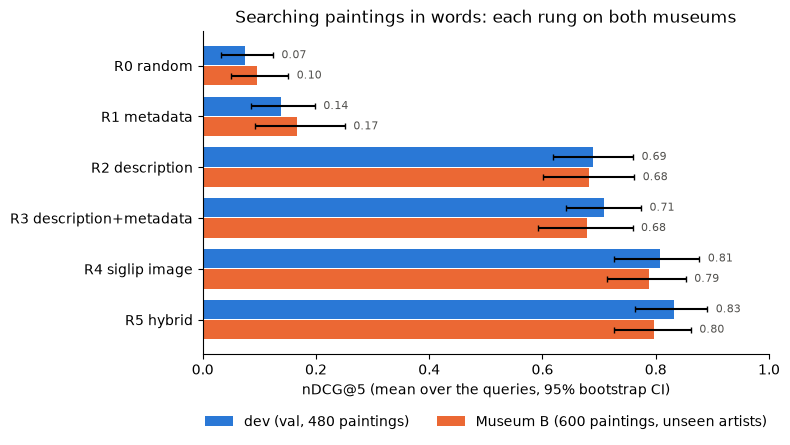

In [2]:
rungs = summary["dev"]["rung"].tolist()
y = np.arange(len(rungs))
fig, ax = plt.subplots(figsize=(8, 4.6))
for offset, corpus in [(-0.2, "dev"), (0.2, "test")]:
    t = summary[corpus]
    err = [t["nDCG@5"] - t["nDCG low"], t["nDCG high"] - t["nDCG@5"]]
    ax.barh(
        y + offset,
        t["nDCG@5"],
        height=0.38,
        xerr=err,
        capsize=2,
        color=COLOURS[corpus],
        label=MUSEUMS[corpus],
    )
    for yi, v, hi in zip(y + offset, t["nDCG@5"], t["nDCG high"]):
        ax.text(hi + 0.015, yi, f"{v:.2f}", va="center", color="#52514e", fontsize=8)
ax.set_yticks(y, rungs)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@5 (mean over the queries, 95% bootstrap CI)")
ax.set_title("Searching paintings in words: each rung on both museums")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "ladder.png", dpi=200)
plt.show()

## 2. The three comparisons fixed in advance

Paired randomization test over queries, Holm correction. Same pairs on both museums.

In [3]:
pairs = [
    ("R2 description", "R1 metadata"),
    ("R4 siglip image", "R1 metadata"),
    ("R5 hybrid", frozen["best_single"]),
]
pd.concat({MUSEUMS[c]: u.compare(per_query[c], pairs) for c in MUSEUMS}).round(3)

system        reference  \
dev (val, 480 paintings)                 0   R2 description      R1 metadata   
                                         1  R4 siglip image      R1 metadata   
                                         2        R5 hybrid  R4 siglip image   
Museum B (600 paintings, unseen artists) 0   R2 description      R1 metadata   
                                         1  R4 siglip image      R1 metadata   
                                         2        R5 hybrid  R4 siglip image   

                                            delta nDCG@5      p  p (Holm)  
dev (val, 480 paintings)                 0         0.551  0.000     0.000  
                                         1         0.670  0.000     0.000  
                                         2         0.024  0.541     0.541  
Museum B (600 paintings, unseen artists) 0         0.517  0.000     0.000  
                                         1         0.622  0.000     0.000  
                                         2         0.010  0.781     0.781

## 3. Where each rung helps (per query category, about 10 queries each, no p-values)

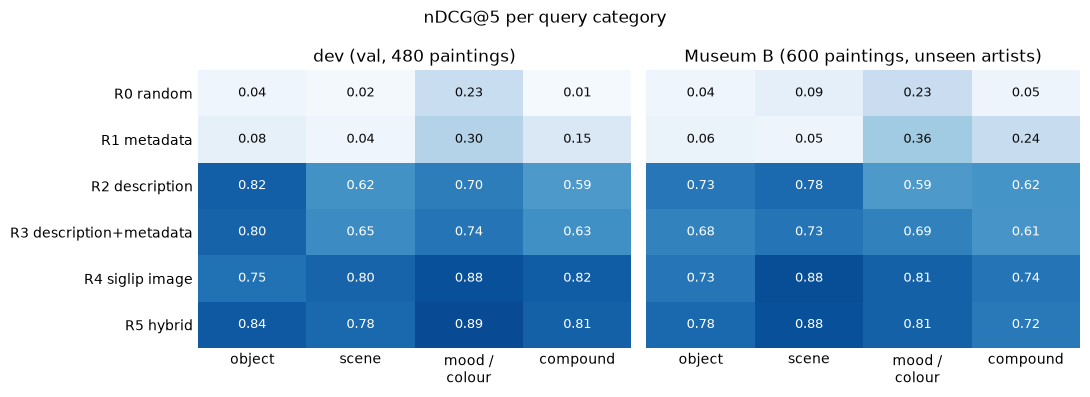

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, corpus in zip(axes, MUSEUMS):
    grid = (
        per_query[corpus]
        .groupby(["rung", "category"], sort=False)["ndcg@5"]
        .mean()
        .unstack()
    )
    grid = grid[["object", "scene", "mood_colour", "compound"]]
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            color="white" if v > 0.55 else "#0b0b0b",
            fontsize=9,
        )
    ax.set_xticks(range(4), ["object", "scene", "mood /\ncolour", "compound"])
    ax.set_yticks(range(len(grid)), grid.index)
    ax.set_title(MUSEUMS[corpus])
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
fig.suptitle("nDCG@5 per query category")
plt.tight_layout()
plt.savefig(FIGURES / "categories.png", dpi=200)
plt.show()

## 4. One query on Museum B: baseline vs hybrid

Recomputed from the cached embeddings (no API call); the numbers under each painting are the judge's grades.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2465.45it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.


[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

...

Loading weights:  21%|██▏       | 87/408 [00:00<00:01, 254.28it/s]

Loading weights:  28%|██▊       | 113/408 [00:00<00:01, 176.69it/s]

Loading weights:  33%|███▎      | 134/408 [00:00<00:01, 182.66it/s]

Loading weights:  60%|█████▉    | 243/408 [00:00<00:00, 425.20it/s]

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 466.93it/s]

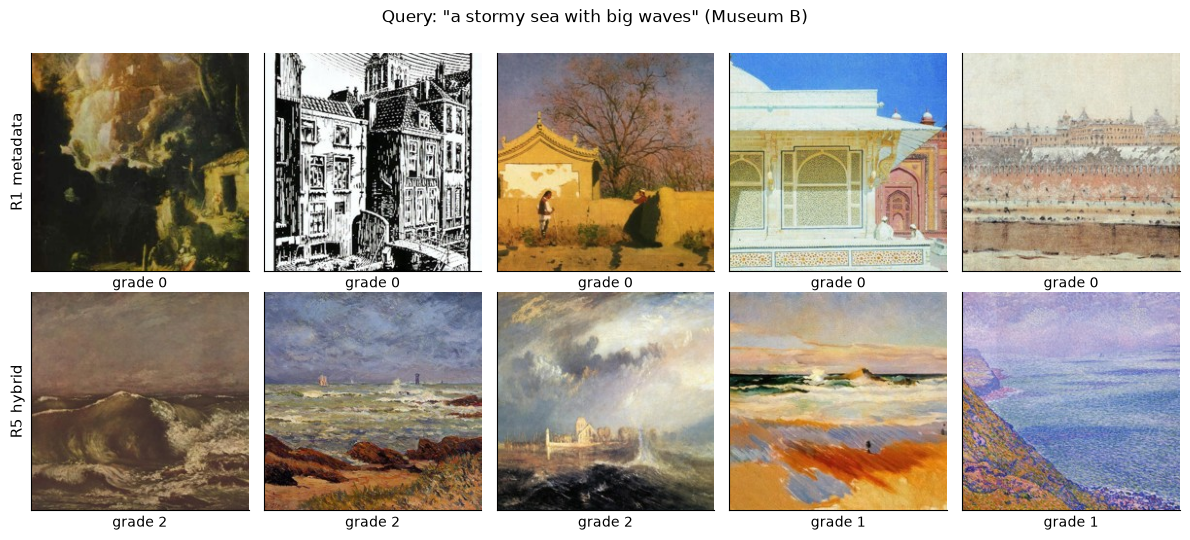

In [5]:
QUERY_ID = "q13"  # "a stormy sea with big waves"
paintings = u.load_corpus("test")
query = u.QUERIES.set_index("query_id").loc[QUERY_ID, "text"]
grades = u.load_qrels("test")[QUERY_ID]
shown = {
    "R1 metadata": u.top_k_ids(u.rung_metadata(paintings, [query]), paintings)[0],
    "R5 hybrid": u.top_k_ids(
        u.rung_hybrid(paintings, [query], u.load_descriptions()), paintings
    )[0],
}
path_of = dict(zip(paintings["id"], paintings["path"]))
fig, axes = plt.subplots(2, u.K, figsize=(12, 5.4))
for row, (rung, ids) in zip(axes, shown.items()):
    for ax, pid in zip(row, ids):
        ax.imshow(Image.open(u.DATA_DIR / path_of[pid]).convert("RGB"))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(f"grade {grades.get(pid, 0)}")
    row[0].set_ylabel(rung, fontsize=11)
fig.suptitle(f'Query: "{query}" (Museum B)')
plt.tight_layout()
plt.savefig(FIGURES / "example_query.png", dpi=150)
plt.show()

Typical answers of the hybrid, not the best ones: for each category, the Museum B query whose R5 nDCG@5 is the
median of its category. Under each painting, the judge's grade.

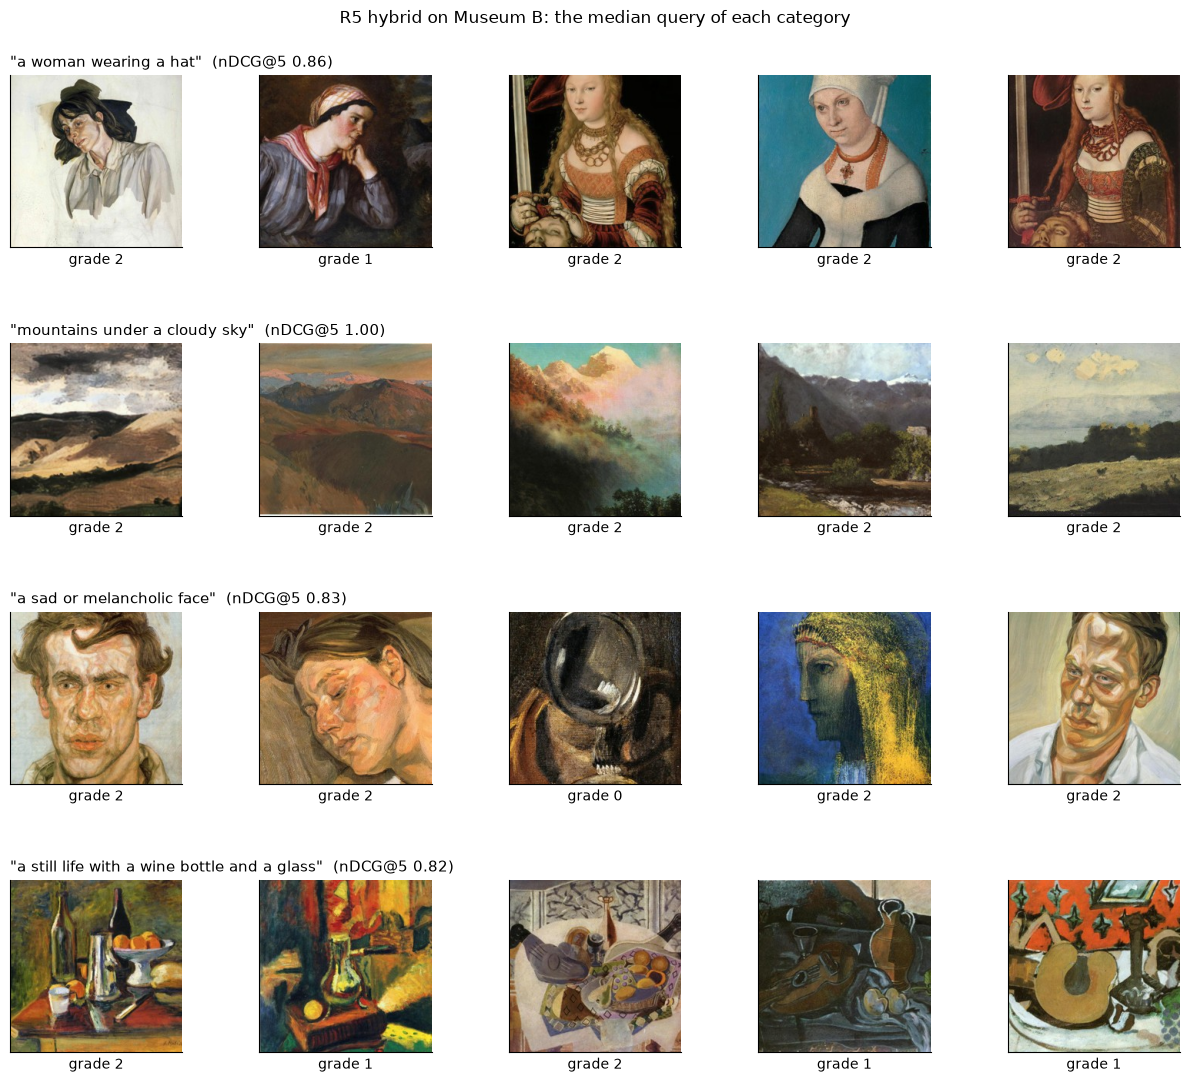

In [6]:
hybrid = per_query["test"][per_query["test"]["rung"] == "R5 hybrid"].sort_values(
    "ndcg@5"
)
picked = (
    hybrid.groupby("category")[["query_id", "ndcg@5"]]
    .agg(lambda col: col.iloc[len(col) // 2])
    .loc[["object", "scene", "mood_colour", "compound"]]
)
texts = u.QUERIES.set_index("query_id")["text"]
scores = u.rung_hybrid(
    paintings, texts[picked["query_id"]].tolist(), u.load_descriptions()
)
fig, axes = plt.subplots(len(picked), u.K, figsize=(12, 2.8 * len(picked)))
for row, (qid, ids, ndcg) in zip(
    axes, zip(picked["query_id"], u.top_k_ids(scores, paintings), picked["ndcg@5"])
):
    grades = u.load_qrels("test")[qid]
    for ax, pid in zip(row, ids):
        ax.imshow(Image.open(u.DATA_DIR / path_of[pid]).convert("RGB"))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(f"grade {grades.get(pid, 0)}")
    row[0].set_title(f'"{texts[qid]}"  (nDCG@5 {ndcg:.2f})', loc="left", fontsize=11)
fig.suptitle("R5 hybrid on Museum B: the median query of each category")
plt.tight_layout()
plt.savefig(FIGURES / "hybrid_examples.png", dpi=110)
plt.show()

## 5. Can the LLM judge be trusted?

150 dev pairs graded blind by a human, on the same scale. `freeze()` required a linear-weighted kappa of at least 0.6.

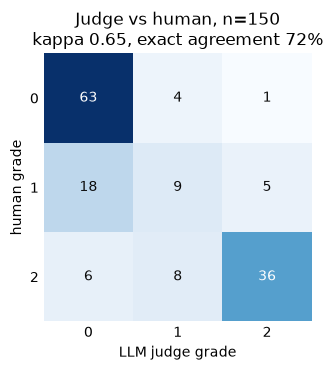

In [7]:
human = json.loads((u.RESULTS_DIR / "qrels_dev_human.json").read_text(encoding="utf-8"))
llm = u.load_qrels("dev")
h, j = zip(*[(g, llm[q][p]) for q, grades in human.items() for p, g in grades.items()])
confusion = pd.crosstab(pd.Series(h, name="human"), pd.Series(j, name="judge"))
exact = np.mean(np.asarray(h) == np.asarray(j))
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(confusion, cmap="Blues")
for (i, k), v in np.ndenumerate(confusion.to_numpy()):
    ax.text(k, i, v, ha="center", va="center", color="white" if v > 30 else "#0b0b0b")
ax.set_xticks(range(3), [0, 1, 2])
ax.set_yticks(range(3), [0, 1, 2])
ax.set_xlabel("LLM judge grade")
ax.set_ylabel("human grade")
ax.set_title(
    f"Judge vs human, n={len(h)}\nkappa {frozen['judge_kappa_dev']:.2f}, exact agreement {exact:.0%}"
)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / "judge_agreement.png", dpi=200)
plt.show()

Most disagreements are on grade 1 ("partial"): the human used it 32 times, the judge often said 0 there. The judge
is stricter, not more generous, so it does not inflate the scores.

## 6. Cost and speed

| | Cost | Where it runs |
|---|---|---|
| Whole project (descriptions, judge, every trial) | **3.38 $** billed by OpenRouter | API |
| VLM description (Qwen3-VL-8B) | about 0.00006 $ per painting, **about 0.06 $ per 1,000 new paintings** | API, once per painting |
| LLM judge (Gemini) | about 0.001 $ per (query, painting) pair, about 1,600 pairs | API, evaluation only |
| Embeddings of the collection (MiniLM, SigLIP) | 0 $, a few minutes | local CPU, once |
| One visitor query | 0 $ | local CPU |

Median time per query on CPU, collection embeddings cached (N04): R1 34 ms, R2 13 ms, R4 82 ms, R5 115 ms. Almost all
the bill is the cost of measuring (judge and trials), not of the system: R4 needs no paid call at all.

## 7. Trade-offs and recommendation

Measured on this laptop's CPU (median per query, collection already indexed). Indexing time and model sizes measured in
the same way; one painting's SigLIP embedding is 768 floats, so 3 KB.

| Option | nDCG@5 dev | nDCG@5 Museum B | Paid API | Indexing a new painting | One query | Model at query time | Parts to maintain |
|---|---|---|---|---|---|---|---|
| R1 metadata | 0.14 | 0.17 | no | needs genre, style, artist | 34 ms | MiniLM, 23 M weights | metadata + 1 model |
| R3 description + metadata | 0.71 | 0.68 | yes, about 0.06 $ per 1,000 paintings | 1 VLM call | about 13 ms | MiniLM, 23 M weights | VLM API + prompt + 1 model |
| **R4 SigLIP image** | **0.81** | **0.79** | **no** | **174 ms on CPU** | **82 ms** | **SigLIP text tower, 110 M weights** | **1 model** |
| R5 hybrid | 0.83 | 0.80 | yes, as R3 | both | 115 ms | both | everything above |

- **What each step buys.** Metadata to description: +0.55 for a paid call per painting and an API to keep alive.
  Description to SigLIP: +0.10 for *less* infrastructure (no API, no text). SigLIP to hybrid: +0.02 on dev and +0.01 on
  Museum B (p = 0.54 and 0.78, so not distinguishable from zero), for the whole description pipeline and +33 ms.
- **What the hybrid would still bring.** Object queries (+0.09 on dev, +0.05 on Museum B, about 12 queries, not
  tested) and religious paintings, where the description finds the iconography (the Virgin, a crucifixion) better than
  the image.
- **Recommendation: SigLIP alone.** Offline, the image tower turns each painting into a vector once (about 3 minutes per
  1,000 paintings on CPU) stored next to its id: 1.8 MB for this museum, 30 MB for 10,000 paintings, in a `.npy` or
  Parquet file. Online, the text tower encodes the visitor's query (about 100 ms) and a dot product with all the vectors
  gives the 5 best (16 ms even for 100,000 paintings): no vector database, no API, no recurring cost. The storage is tiny;
  the model is not (110 M weights, about 440 MB in float32), but it runs on a plain CPU.
- **When to choose the hybrid instead.** If the museum wants the descriptions anyway (to show or read out why a
  painting was proposed, for accessibility), the hybrid comes almost free and helps on objects.

## 8. Perspectives (not built)

- **The two branches are complementary**: their per-query scores are barely correlated (0.09 on dev, 0.37 on
  Museum B). Choosing the better branch for each query would give 0.88 and 0.84: about +0.05 above the hybrid, a
  ceiling that a smarter fusion can only approach.
- **The best branch depends on the genre**: the description wins on religious paintings on both museums, the image on
  portraits. A fusion learned on the scores and on the genre *predicted by our vision model* would link the two halves
  of the project; with 40 queries, its gain (at most a few points) would not be measurable here.
- **Re-ranking**: let a VLM look at SigLIP's top 20 with the query in hand, the way the judge does, at the price of
  seconds and a paid call per query.